## Imports

In [21]:
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt

## 1. Non-isomorphic graphs

8 vertices ; 9 edges ; [2, 2, 2, 2, 2, 2, 3, 3]
8 vertices ; 9 edges ; [2, 2, 2, 2, 2, 2, 3, 3]


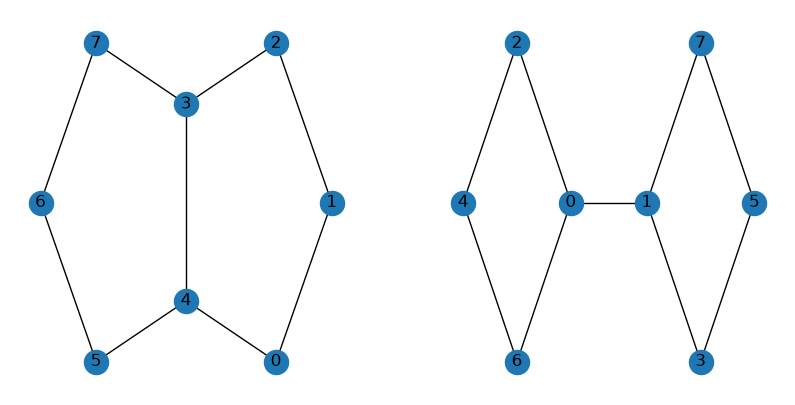

In [ ]:
pentagons_coordinates = np.array([
  [ 1.3143277805, -4.0450849720],
  [ 4.2532540420, 0.0],
  [ 1.3143277805, 4.0450849720],
  [ -3.4409548010, 2.5],
  [ -3.4409548010, -2.5],
  [ -8.1962373825, -4.0450849720],
  [-11.1351636440, 0.0],
  [ -8.1962373825, 4.0450849720]
])

squares_coordinates = np.array([
  [ 3.5355339060, 0.0],
  [ 8.5355339060, 0.0],
  [ 0.0, 3.5355339060],
  [12.0710678120, -3.5355339060],
  [-3.5355339060, 0.0],
  [15.6066017180, 0.0],
  [ 0.0, -3.5355339060],
  [12.0710678120, 3.5355339060]
])

def createGraph(graph_coordinates, N):
  G = nx.Graph()
  for i in range(N):
    for j in range(N):
      u1, v1 = graph_coordinates[i]
      u2, v2 = graph_coordinates[j]
      if u1 == u2 and v1 == v2:
        continue
      else:
        dst = np.sqrt((u2 - u1)**2 + (v2 - v1)**2)
        if dst <= 5.5:
          G.add_edge(i, j)

  print(f"{len(G.nodes)} vertices ; {len(G.edges)} edges ; {sorted(dict(G.degree()).values())}")

  return G

pentagon_graph = createGraph(pentagons_coordinates, 8)
square_graph = createGraph(squares_coordinates, 8)

fig, axs = plt.subplots(1, 2, figsize=(10, 5))

nx.draw(pentagon_graph, pos=pentagons_coordinates, with_labels=True, ax=axs[0])
nx.draw(square_graph, pos=squares_coordinates, with_labels=True, ax=axs[1])
plt.show()


In [30]:
print(nx.is_isomorphic(pentagon_graph, square_graph))

False


**In a few sentences, explain why the descriptors computed in Q1 are insufficient to fully characterize a graph.**

The previous computed descriptors don't characterize the geometry of the graph (cycle, symetries, ...). Only static parameters.

## 2. Embedding graphs into neutral-atom registers

/usr/local/lib/python3.13/dist-packages/pulser/register/register.py:58: DeprecationWarning: Usage of `int`s or any non-`str`types as `QubitId`s will be deprecated. Define your `QubitId`s as `str`s, prefer setting `prefix='q'` when using classmethods, as that will become the new default once `int` qubit IDs become invalid.
  super().__init__(qubits, **kwargs)


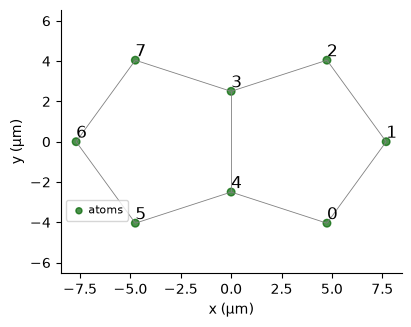

/usr/local/lib/python3.13/dist-packages/pulser/register/register.py:58: DeprecationWarning: Usage of `int`s or any non-`str`types as `QubitId`s will be deprecated. Define your `QubitId`s as `str`s, prefer setting `prefix='q'` when using classmethods, as that will become the new default once `int` qubit IDs become invalid.
  super().__init__(qubits, **kwargs)


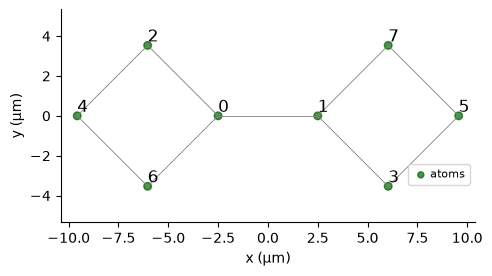

In [115]:
from pulser import Register, Sequence, Pulse
from pulser.devices import AnalogDevice, DigitalAnalogDevice

pentagon_reg = Register.from_coordinates(pentagons_coordinates)
pentagon_reg.draw(blockade_radius=5.5)

square_reg = Register.from_coordinates(squares_coordinates)
square_reg.draw(blockade_radius=5.5)

## 3. Analog control and quantum evolution

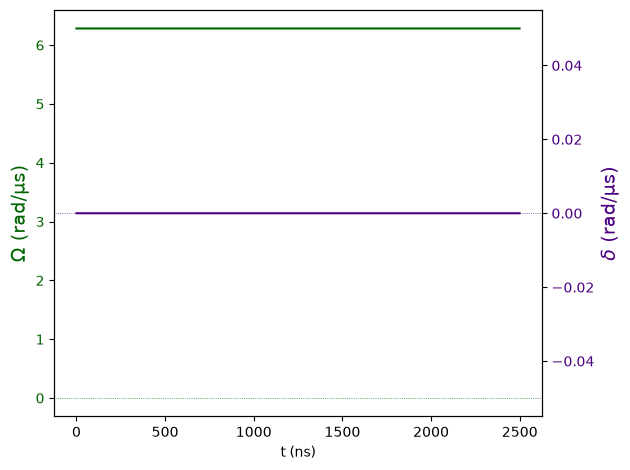

In [116]:
pulse = Pulse.ConstantPulse(duration=2.5e3, amplitude=2*np.pi, detuning=0, phase=0)
pulse.draw()

In [117]:
pentagon_seq = Sequence(pentagon_reg, DigitalAnalogDevice)
pentagon_seq.declare_channel('ch0', 'rydberg_global')
pentagon_seq.add(pulse, "ch0")
pentagon_seq.measure("ground-rydberg")

square_seq = Sequence(square_reg, DigitalAnalogDevice)
square_seq.declare_channel('ch0', 'rydberg_global')
square_seq.add(pulse, "ch0")
square_seq.measure("ground-rydberg")

## 4. From measurement bit strings to a graph signature

/tmp/ipykernel_2650/461730571.py:4: DeprecationWarning: 'QutipBackend' is deprecated. Please use 'pulser_simulation.QutipBackendV2' instead.
  sim = pulser_simulation.QutipBackend(graph_seq)
/tmp/ipykernel_2650/461730571.py:4: DeprecationWarning: 'QutipBackend' is deprecated. Please use 'pulser_simulation.QutipBackendV2' instead.
  sim = pulser_simulation.QutipBackend(graph_seq)


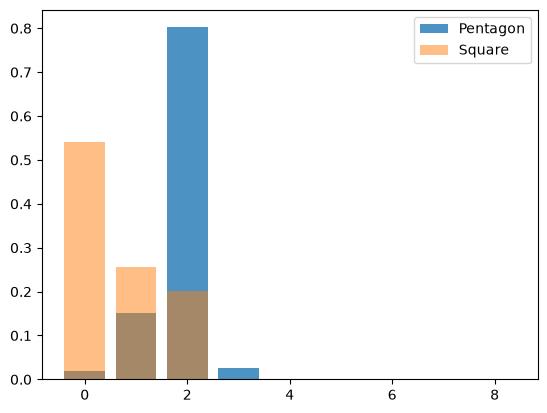

In [ ]:
import pulser_simulation

def simulate_graph(graph_seq):
  sim = pulser_simulation.QutipBackend(graph_seq)
  res = sim.run()

  results = res.sample_final_state(N_samples=1000)

  results_distribution = dict()
  for i in range(9):
    results_distribution[i] = 0
  for key, value in results.items():
    k = 0
    for i in range(len(key)):
      if key[i] == '1': k += 1

    results_distribution[k] += value / 1000

  return results_distribution

pentagon_distribution = simulate_graph(pentagon_seq)
square_distribution = simulate_graph(square_seq)

plt.bar(pentagon_distribution.keys(), pentagon_distribution.values(), alpha=0.8, label="Pentagon")
plt.bar(square_distribution.keys(), square_distribution.values(), alpha=0.5, label="Square")
plt.legend()

**Why the simple act of counting excited atoms can still retain information about the underlying graph geometry ?**

The regions of the graphs (each of which affects a certain number of atoms) are not located in the same place in space. It means that the clusters of atoms that interact with one another are not located in the same place.

## 5. Quantifying the difference between the two distributions

In [118]:
def H(P):
  return -np.sum(P[P>0] * np.log2(P[P>0]))

def JSD_entropy(P, Q):
  return H((P + Q) / 2) - (H(P) + H(Q)) / 2

print(JSD_entropy(np.array(list(pentagon_distribution.values())), np.array(list(square_distribution.values()))))

0.24136482414920302


0 <= JSD(P, Q) <= 1

JSD is equal to 0 if distributions are exactly the same. The more different they are, the higher is the JSD value.

## 6. Time-resolved quantum features

/tmp/ipykernel_2650/461730571.py:4: DeprecationWarning: 'QutipBackend' is deprecated. Please use 'pulser_simulation.QutipBackendV2' instead.
  sim = pulser_simulation.QutipBackend(graph_seq)
/tmp/ipykernel_2650/461730571.py:4: DeprecationWarning: 'QutipBackend' is deprecated. Please use 'pulser_simulation.QutipBackendV2' instead.
  sim = pulser_simulation.QutipBackend(graph_seq)
/tmp/ipykernel_2650/461730571.py:4: DeprecationWarning: 'QutipBackend' is deprecated. Please use 'pulser_simulation.QutipBackendV2' instead.
  sim = pulser_simulation.QutipBackend(graph_seq)
/tmp/ipykernel_2650/461730571.py:4: DeprecationWarning: 'QutipBackend' is deprecated. Please use 'pulser_simulation.QutipBackendV2' instead.
  sim = pulser_simulation.QutipBackend(graph_seq)
/tmp/ipykernel_2650/461730571.py:4: DeprecationWarning: 'QutipBackend' is deprecated. Please use 'pulser_simulation.QutipBackendV2' instead.
  sim = pulser_simulation.QutipBackend(graph_seq)
/tmp/ipykernel_2650/461730571.py:4: Deprecati

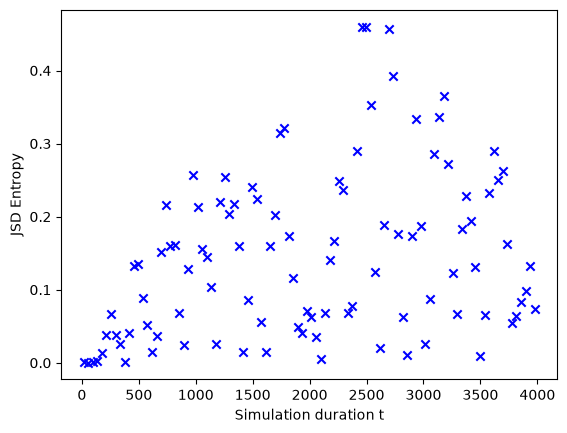

In [123]:
JSD_entropies = []

for t in range(16, 4000, 40):
  pulse = Pulse.ConstantPulse(duration=t, amplitude=2*np.pi, detuning=0, phase=0)

  pentagon_seq = Sequence(pentagon_reg, DigitalAnalogDevice)
  pentagon_seq.declare_channel('ch0', 'rydberg_global')
  pentagon_seq.add(pulse, "ch0")
  pentagon_seq.measure("ground-rydberg")

  square_seq = Sequence(square_reg, DigitalAnalogDevice)
  square_seq.declare_channel('ch0', 'rydberg_global')
  square_seq.add(pulse, "ch0")
  square_seq.measure("ground-rydberg")

  pentagon_distribution = simulate_graph(pentagon_seq)
  square_distribution = simulate_graph(square_seq)

  entropy = JSD_entropy(np.array(list(pentagon_distribution.values())), np.array(list(square_distribution.values())))
  JSD_entropies.append((t, entropy))
  plt.scatter(t, entropy, marker='x', color='blue')

plt.xlabel("Simulation duration t")
plt.ylabel("JSD Entropy")
plt.show()

In [136]:
JSD_entropies = np.array(JSD_entropies)

max = np.max(JSD_entropies[:,1])
i_max = np.argmax(JSD_entropies[:,1])
t_max = JSD_entropies[i_max][0]

print(f't = {t_max}; JSD = {max}')

t = 2496.0; JSD = 0.4599890081387852


In order to distinguish between the graphs as precisely as possible (if they are different), we seek the time t that maximizes the JSD entropy.

We want the distributions to be as different as possible.